<a href="https://colab.research.google.com/github/2025cishaunaquindsouzab-sketch/Dav-Lab-Programs-4Ni25ci100/blob/main/4NI25CI100_EXP_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Please upload 'Student_Performance.csv' below:


Saving Student_Performance.csv to Student_Performance.csv

--- Dataset Preview ---
   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   

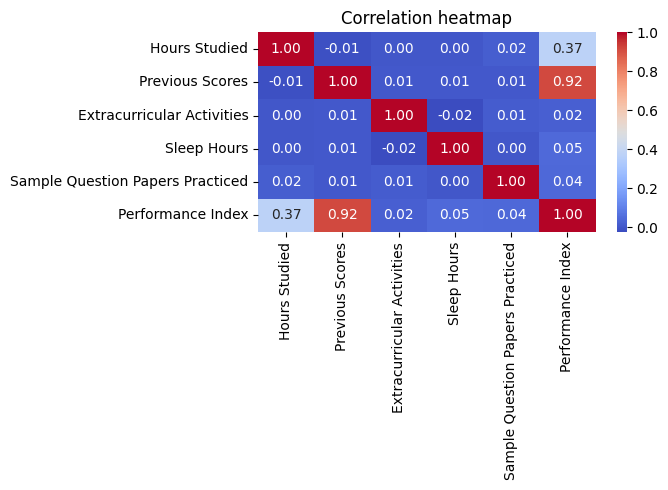


=== SIMPLE LINEAR REGRESSION ===
Intercept (b0): 41.436634826535744
Slope (b1) : 2.784300441170774
R2 : 0.13160425385996788
RMSE : 17.93919001285204


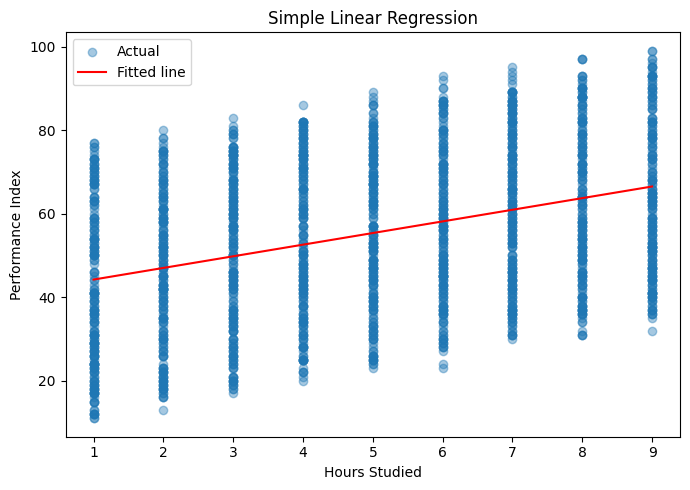


=== MULTIPLE LINEAR REGRESSION ===
Intercept: -33.92194621555638
 Hours Studied                       2.8525
 Previous Scores                     1.0170
 Extracurricular Activities          0.6086
 Sleep Hours                         0.4769
 Sample Question Papers Practiced    0.1918
R2 : 0.9889832909573145
Adjusted R2 : 0.9889556663107681
RMSE : 2.0205515085050054


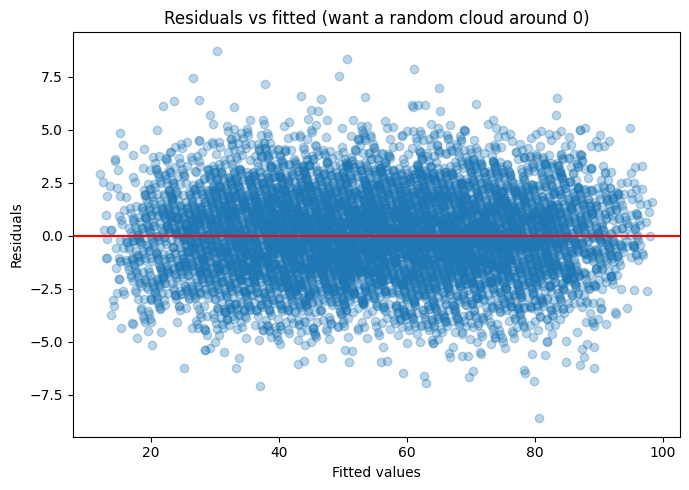

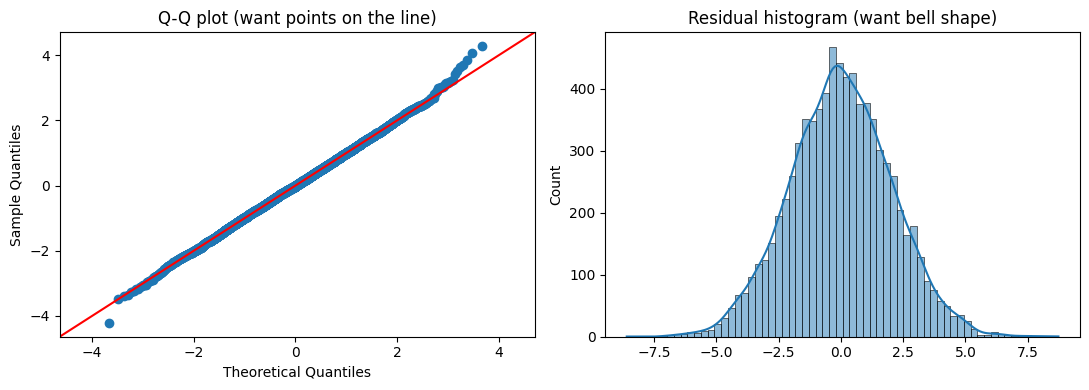

Breusch-Pagan p-value: 0.2396245087908097
Durbin-Watson: 2.0331060225040156

VIF:
                             Feature       VIF
1                     Hours Studied  1.000387
2                   Previous Scores  1.000243
3        Extracurricular Activities  1.000428
4                       Sleep Hours  1.000461
5  Sample Question Papers Practiced  1.000320


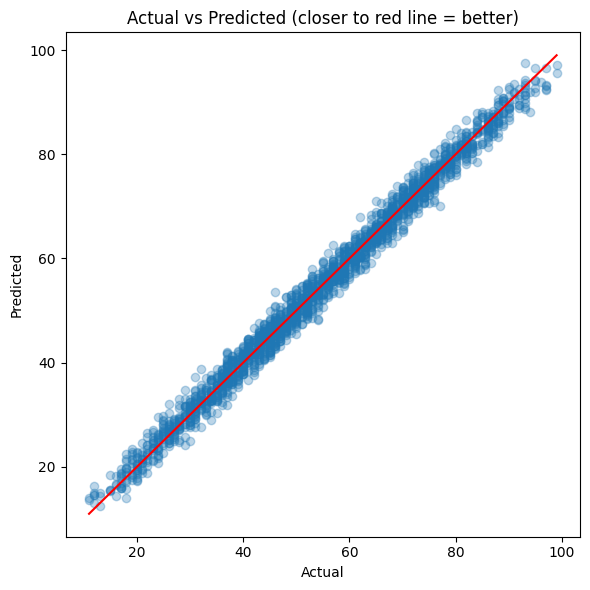

In [5]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from google.colab import files

# 1. Upload and Load Data
print("Please upload 'Student_Performance.csv' below:")
uploaded = files.upload()

# Get the uploaded file name
file_name = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("\n--- Dataset Preview ---")
print(df.head())
print(df.info())
print(df.describe())
print("Missing values:\n", df.isnull().sum())

# Map categorical column
df["Extracurricular Activities"] = df["Extracurricular Activities"].map({"Yes": 1, "No": 0})

# Correlation Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig("01_correlation.png")
plt.show()

# 2. Simple Linear Regression
X_simple = df[["Hours Studied"]]
y = df["Performance Index"]

Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(Xs_train, ys_train)

print("\n=== SIMPLE LINEAR REGRESSION ===")
print("Intercept (b0):", simple_model.intercept_)
# FIX 1: Accessing the slope array coefficient explicitly
print("Slope (b1) :", simple_model.coef_[0])

sys_pred = simple_model.predict(Xs_test)
print("R2 :", r2_score(ys_test, sys_pred))
print("RMSE :", np.sqrt(mean_squared_error(ys_test, sys_pred)))

# Plot the fitted line
plt.figure(figsize=(7, 5))
plt.scatter(Xs_test, ys_test, alpha=0.4, label="Actual")
plt.plot(
    Xs_test.sort_values("Hours Studied"),
    simple_model.predict(Xs_test.sort_values("Hours Studied")),
    color="red",
    label="Fitted line"
)
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.title("Simple Linear Regression")
plt.legend()
plt.savefig("02_simple_fit.png")
plt.tight_layout()
plt.show()

# 3. Multiple Linear Regression
X = df.drop(columns="Performance Index")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

multi_model = LinearRegression()
multi_model.fit(X_train, y_train)

print("\n=== MULTIPLE LINEAR REGRESSION ===")
print("Intercept:", multi_model.intercept_)
for name, coef in zip(X.columns, multi_model.coef_):
    print(f" {name:35s} {coef:.4f}")

# Model evaluation metrics
y_pred = multi_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
n, p = X_test.shape
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("R2 :", r2)
print("Adjusted R2 :", adj_r2)
print("RMSE :", rmse)

# 4. Checking Assumptions
X_train_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_train_sm).fit()
fitted = ols.fittedvalues
resid = ols.resid

# 4a. Residuals vs Fitted
plt.figure(figsize=(7, 5))
plt.scatter(fitted, resid, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs fitted (want a random cloud around 0)")
plt.tight_layout()
plt.savefig("03_resid_vs_fitted.png")
plt.show()

# 4b. Normality of residuals
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sm.qqplot(resid, line="45", fit=True, ax=ax[0])
ax[0].set_title("Q-Q plot (want points on the line)")
sns.histplot(resid, kde=True, ax=ax[1])
ax[1].set_title("Residual histogram (want bell shape)")
plt.tight_layout()
plt.savefig("04_normality.png")
plt.show()

# 4c. Homoscedasticity test
bp_stat, bp_p, _, _ = het_breuschpagan(resid, X_train_sm)
print("Breusch-Pagan p-value:", bp_p)

# 4d. Independence of errors
print("Durbin-Watson:", durbin_watson(resid))

# 4e. Multicollinearity (VIF)
# FIX 2: Removed the broken duplicate declaration line snippet
vif = pd.DataFrame()
vif["Feature"] = X_train_sm.columns
vif["VIF"] = [variance_inflation_factor(X_train_sm.values, i) for i in range(X_train_sm.shape[1])]
print(f"\nVIF:\n", vif[vif["Feature"] != "const"])

# 5. Final Plot: Actual vs Predicted
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.3)

# FIX 3: Replaced broken y_min() / y_max() function calls with the actual series min/max boundaries
y_min_val, y_max_val = y_test.min(), y_test.max()
plt.plot([y_min_val, y_max_val], [y_min_val, y_max_val], color="red")

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted (closer to red line = better)")
plt.tight_layout()
plt.savefig("05_actual_vs_pred.png")
plt.show()